# Imports

In [27]:
from IPython.display import display, HTML
display(HTML("<style>.container { width:95% !important; }</style>"))
import warnings
warnings.filterwarnings("ignore") # umap deprecation warnings related to numba do not concern us.

In [28]:
import functools as fn
import itertools as it

import numpy as np
import pandas as pd

import sklearn
from sklearn.utils import Bunch
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.manifold import TSNE
from sklearn.preprocessing import FunctionTransformer
from umap import umap_ as umap

import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import plotnine as pn
from plotnine import *

In [29]:
import scanpy as sc

from scboolseq.utils import parse_data_directory, parse_pickles
from scboolseq import scBoolSeq

In [30]:
# Source - https://stackoverflow.com/a/52858398
# Posted by user4234032, modified by community. See post 'Timeline' for change history
# Retrieved 2026-04-22, License - CC BY-SA 4.0

import os
notebook_path = os.path.abspath("1. Clusterization.ipynb")

In [31]:
from celltypist import models
from scipy.sparse import csr_matrix

In [32]:
%ls *csv

dataset_hvgs.csv*                    scboolseq_inferred_observations.csv*
sc_metadata.csv*


## HVG binarization

In [33]:
data = pd.read_csv("dataset_hvgs.csv", index_col=0)
print(data.shape)
data.head()

(14915, 469)


,Sbspon,Mcm3,Il1rl1,Il18r1,Sdpr,Stat1,Serpine2,Hjurp,Otos,Pam,...,Gda,Vldlr,Ifit3,Ifit1,Kif20b,Kif11,Hells,Dntt,Dusp5,Pdcd4
AAACCTGAGTTCGATC-1_0,0.0,0.000000,0.0,0.0,4.595516,0.00000,0.000000,5.283602,0.0,0.000000,...,0.000000,0.0,0.0,0.0,0.000000,0.0,0.000000,0.000000,0.0,4.595516
AAACCTGCAATCGGTT-1_0,0.0,0.000000,0.0,0.0,0.000000,0.00000,4.730565,0.000000,0.0,0.000000,...,0.000000,0.0,0.0,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.000000
AAACCTGCACACGCTG-1_0,0.0,4.878511,0.0,0.0,0.000000,0.00000,3.795001,0.000000,0.0,0.000000,...,3.795001,0.0,0.0,0.0,0.000000,0.0,3.795001,5.972038,0.0,3.795001
AAACCTGCACGGATAG-1_0,0.0,4.986715,0.0,0.0,0.000000,0.00000,0.000000,0.000000,0.0,3.620698,...,0.000000,0.0,0.0,0.0,0.000000,0.0,3.620698,0.000000,0.0,4.701306
AAACCTGCATCATCCC-1_0,0.0,3.799260,0.0,0.0,0.000000,3.79926,0.000000,0.000000,0.0,0.000000,...,0.000000,0.0,0.0,0.0,4.481151,0.0,3.799260,0.000000,0.0,3.799260


In [42]:
%%time
scbool = scBoolSeq(
    dor_threshold=0.9, # To retain one of the markers, otherwise it will be marked as discarded due to its high dropout rate
    confidence=.75 # To maximize binarization
)
scbool.fit(data)

CPU times: user 3.25 s, sys: 1.43 s, total: 4.68 s
Wall time: 4.07 s


,confidence,0.75
,dor_threshold,0.9
,covariance_type,'full'
,margin_quantile,0.05
,alpha,0.0
,zeroinf_binarizer,'zero_or_not'
,zeroes_are,nan
,amplitude_threshold,10.0
,half_life_parameter,'MeanNZ'
,warm_start,True
,require_df,True


In [43]:
scbool.criteria_.Category.value_counts()

Category
Discarded    203
Bimodal      150
ZeroInf      116
Name: count, dtype: int64

In [40]:
from markers import (
    positive_markers, # function to generate a configuration dictionnary from a set of marker genes
    states_and_markers, # Dictionnary containing phenotypes and their marker genes
)

marker_genes = pd.Series(list(set(it.chain.from_iterable(states_and_markers.values()))))
marker_genes.shape[0]

48

In [11]:
print("Czy 'Kif1' jest w var?", "Kif1" in data.columns)

Czy 'Kif1' jest w var? False


In [12]:
marker_genes = marker_genes[marker_genes.isin(data.columns)]

In [13]:
#missing_genes = ['Slamf1', 'Cd79a', 'Zbtb7a', 'Tcrg-C4', 'Procr', 'Ly6d', 'Kif1', 'Vwf']
#missing_genes = marker_genes.isin(data.columns)

In [14]:
#export_markers = hvgs.append(pd.Index(marker_genes[~marker_genes.isin(hvgs) & marker_genes.isin(merged_adata.var_names)]))

In [58]:
type(states_and_markers['iHSC'])

set

In [59]:
states_and_markers.items()

dict_items([('iHSC', {'Fli1', 'Slamf1', 'Bclaf1', 'Kdm5b', 'Srf', 'Procr', 'Alcam', 'Foxp1'}), ('srHSC', {'Srf', 'Zbtb7a', 'Mki67', 'Hmmr', 'Ccnb1', 'Bclaf1'}), ('ifnHSC', {'Irf7', 'Stat1', 'Irf1', 'Irf9'}), ('qHSC', {'Fli1', 'Cdkn1a', 'Gata2', 'Junb', 'Tal1', 'Egr1', 'Nr4a1'}), ('preDiff', {'Myc', 'Sox4', 'Cd34', 'Hoxa9', 'Spi1'}), ('pLymph', {'Zbtb16', 'Ly6d', 'Il7r', 'Cd79a', 'Gata3', 'Trp53inp1', 'Tcrg-C4', 'Ikzf1'}), ('pNeuMast', {'Elane', 'Mcpt8', 'Cebpa', 'Fcer1a', 'Hdc', 'Spi1'}), ('pEr', {'Kif1', 'Klf1', 'Zfpm1', 'Gata1'}), ('pMk', {'Fli1', 'Zfpm1', 'Gata1', 'Clu', 'Uhrf1', 'Pf4', 'Vwf'})])

In [98]:
#correction
marker_genes = marker_genes[~marker_genes.isin(missing_genes)]
for (obs, markers) in states_and_markers.items():
    #print(obs)
    states_and_markers[obs] = states_and_markers[obs].difference(set(missing_genes))

In [36]:
scbool.criteria_.loc[marker_genes, :].Category.value_counts()

KeyError: "['Ly6d', 'Zbtb16', 'Kdm5b', 'Irf9', 'Procr', 'Fli1', 'Zbtb7a', 'Tcrg-C4', 'Vwf', 'Tal1', 'Zfpm1', 'Ikzf1', 'Foxp1', 'Bclaf1', 'Cd79a', 'Srf', 'Kif1', 'Hoxa9', 'Slamf1', 'Spi1'] not in index"

In [44]:
%time 
bin_data = scbool.binarize(data)

CPU times: user 2 μs, sys: 0 ns, total: 2 μs
Wall time: 3.81 μs


NotFittedError: This GaussianMixtureBinarizer instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.

In [64]:
bin_data?

Object `bin_data` not found.


In [101]:
partial_bin_configs = bin_data[marker_genes]
partial_bin_configs.fillna('').head()

,Myc,Il7r,Nr4a1,Cdkn1a,Gata3,Trp53inp1,Stat1,Spi1,Ikzf1,Ccnb1,...,Cebpa,Hdc,Clu,Irf1,Mcpt8,Hmmr,Cd34,Srf,Mki67,Tal1
AAACCTGAGTTCGATC-1_0,0.0,,,,0.0,,0.0,1.0,0.0,,...,,,0.0,0.0,0.0,,1.0,,,0.0
AAACCTGCAATCGGTT-1_0,1.0,,,,1.0,,0.0,1.0,0.0,,...,,,0.0,0.0,0.0,,0.0,,,1.0
AAACCTGCACACGCTG-1_0,0.0,1.0,,,1.0,,0.0,0.0,1.0,,...,,,0.0,0.0,1.0,,1.0,,,0.0
AAACCTGCACGGATAG-1_0,1.0,,,,0.0,,0.0,1.0,0.0,,...,1.0,,0.0,0.0,1.0,,0.0,,,1.0
AAACCTGCATCATCCC-1_0,1.0,,1.0,,0.0,,1.0,1.0,0.0,,...,,,0.0,0.0,0.0,,1.0,,,0.0


In [102]:
prior_markers = {
    obs: positive_markers(markers)
    for obs, markers
    in states_and_markers.items()
}
prior_markers

{'iHSC': {'Kdm5b': 1,
  'Bclaf1': 1,
  'Alcam': 1,
  'Srf': 1,
  'Foxp1': 1,
  'Fli1': 1},
 'srHSC': {'Bclaf1': 1, 'Hmmr': 1, 'Srf': 1, 'Ccnb1': 1, 'Mki67': 1},
 'ifnHSC': {'Irf9': 1, 'Irf1': 1, 'Irf7': 1, 'Stat1': 1},
 'qHSC': {'Egr1': 1,
  'Nr4a1': 1,
  'Cdkn1a': 1,
  'Gata2': 1,
  'Tal1': 1,
  'Fli1': 1,
  'Junb': 1},
 'preDiff': {'Myc': 1, 'Hoxa9': 1, 'Spi1': 1, 'Cd34': 1, 'Sox4': 1},
 'pLymph': {'Il7r': 1, 'Gata3': 1, 'Trp53inp1': 1, 'Ikzf1': 1, 'Zbtb16': 1},
 'pNeuMast': {'Cebpa': 1,
  'Hdc': 1,
  'Spi1': 1,
  'Mcpt8': 1,
  'Elane': 1,
  'Fcer1a': 1},
 'pEr': {'Gata1': 1, 'Klf1': 1, 'Zfpm1': 1},
 'pMk': {'Pf4': 1, 'Gata1': 1, 'Clu': 1, 'Zfpm1': 1, 'Uhrf1': 1, 'Fli1': 1}}

In [103]:
obs_by_markers = {}
for _conf, _marker_dict in prior_markers.items():
    # Build a query with the genes and their values, configuration by configuration
    _conf_query = " & ".join(f"{_gene} == {_value:.1f}" for _gene, _value in _marker_dict.items())
    _matching = partial_bin_configs.fillna(-1.0).query(_conf_query).index
    obs_by_markers.update({_conf: _matching})

In [104]:
number_of_matching_obs = {conf: idx.shape[0] for conf, idx in obs_by_markers.items()}
number_of_matching_obs

{'iHSC': 15,
 'srHSC': 42,
 'ifnHSC': 143,
 'qHSC': 71,
 'preDiff': 888,
 'pLymph': 2,
 'pNeuMast': 20,
 'pEr': 95,
 'pMk': 7}

In [105]:
percentage_matching = {conf: 100*idx.shape[0]/partial_bin_configs.shape[0] for conf, idx in obs_by_markers.items()}
{k: f"{v:.2f}" for k, v in percentage_matching.items()}

{'iHSC': '0.10',
 'srHSC': '0.28',
 'ifnHSC': '0.96',
 'qHSC': '0.48',
 'preDiff': '5.95',
 'pLymph': '0.01',
 'pNeuMast': '0.13',
 'pEr': '0.64',
 'pMk': '0.05'}

In [106]:
int(sum(percentage_matching.values()))

8

## Check for multi-labelled cells

In [107]:
intersections_of_all_combinations = list(map(
    lambda x: (
        x, 
        obs_by_markers[x[0]].intersection(obs_by_markers[x[1]]).shape[0]
    ), 
    it.combinations(obs_by_markers, 2) # All possible pairwise combinations, without replacement
)) # This will contain a list of nested tuples as follows: ((conf_1, conf_2), number_of_cells_in_both_groups)

In [108]:
non_null_intersections = list(filter(
    lambda p1_p2_shape: p1_p2_shape[-1].shape[0] > 0,
    map(
        lambda x: (x, obs_by_markers[x[0]].intersection(obs_by_markers[x[1]])), 
        it.combinations(obs_by_markers, 2)
    )
))
print(len(non_null_intersections))
len(non_null_intersections) / len(intersections_of_all_combinations)

15


0.4166666666666667

In [109]:
{(c1, c2): len(idx) for ((c1, c2), idx) in non_null_intersections}

{('iHSC', 'srHSC'): 2,
 ('iHSC', 'qHSC'): 1,
 ('iHSC', 'preDiff'): 1,
 ('srHSC', 'ifnHSC'): 1,
 ('srHSC', 'preDiff'): 7,
 ('srHSC', 'pEr'): 2,
 ('srHSC', 'pMk'): 1,
 ('ifnHSC', 'qHSC'): 2,
 ('ifnHSC', 'preDiff'): 17,
 ('qHSC', 'preDiff'): 9,
 ('qHSC', 'pNeuMast'): 1,
 ('preDiff', 'pNeuMast'): 2,
 ('preDiff', 'pEr'): 4,
 ('preDiff', 'pMk'): 1,
 ('pEr', 'pMk'): 3}

In [110]:
unambiguous_observations = {}
for _phenotype, _idx in obs_by_markers.items():
    _unambiguous = fn.reduce(
        lambda x, y: x.difference(y),
        [idx for ((p1, p2), idx) in non_null_intersections if p1 == _phenotype or p2 == _phenotype],
        _idx
    )
    unambiguous_observations.update({_phenotype: _unambiguous})
    _n_unambiguous = _unambiguous.shape[0]
    print(f"{_phenotype} has {_n_unambiguous} matching unambiguous configurations, {100*_n_unambiguous/number_of_matching_obs[_phenotype]:.2f}% of matching configs")
    
unlabelled_idx = data.index.difference(fn.reduce(lambda x, y: x.union(y), unambiguous_observations.values()))

iHSC has 12 matching unambiguous configurations, 80.00% of matching configs
srHSC has 32 matching unambiguous configurations, 76.19% of matching configs
ifnHSC has 124 matching unambiguous configurations, 86.71% of matching configs
qHSC has 59 matching unambiguous configurations, 83.10% of matching configs
preDiff has 851 matching unambiguous configurations, 95.83% of matching configs
pLymph has 2 matching unambiguous configurations, 100.00% of matching configs
pNeuMast has 18 matching unambiguous configurations, 90.00% of matching configs
pEr has 88 matching unambiguous configurations, 92.63% of matching configs
pMk has 4 matching unambiguous configurations, 57.14% of matching configs


In [111]:
color_map = {
    "Unknown": "#e6e6e6",   # gray
    "iHSC": "#1f77b4",      # blue
    "srHSC": "#17becf",     # light blue / cyan
    "ifnHSC": "#9467bd",    # purple
    "qHSC": "#2ca02c",      # green
    "preDiff": "#ff7f0e",   # orange
    "pLymph": "#e377c2",    # pink
    "pNeuMast": "#8c564b",  # brown
    "pEr": "#d62728",       # red
    "pMk": "#bcbd22",       # olive
}

In [112]:
unambiguous_metadata = pd.DataFrame({
    "label": "Unknown"
}, index=data.index)
for _conf, _idx in unambiguous_observations.items():
    unambiguous_metadata.loc[_idx, "label"] = _conf

color = unambiguous_metadata.label.map(color_map)
color.name = "label_color"
unambiguous_metadata = unambiguous_metadata.join(color)

print(100 * unambiguous_metadata.label.value_counts() / unambiguous_metadata.shape[0])
unambiguous_metadata.head()

label
Unknown     92.021455
preDiff      5.705665
ifnHSC       0.831378
pEr          0.590010
qHSC         0.395575
srHSC        0.214549
pNeuMast     0.120684
iHSC         0.080456
pMk          0.026819
pLymph       0.013409
Name: count, dtype: float64


,label,label_color
AAACCTGAGTTCGATC-1_0,Unknown,#e6e6e6
AAACCTGCAATCGGTT-1_0,Unknown,#e6e6e6
AAACCTGCACACGCTG-1_0,Unknown,#e6e6e6
AAACCTGCACGGATAG-1_0,Unknown,#e6e6e6
AAACCTGCATCATCCC-1_0,Unknown,#e6e6e6


In [113]:
unambiguous_metadata.query("label != 'Unknown'").shape[0] / unambiguous_metadata.shape[0]

0.07978545088836742

In [114]:
EXPORT_METADATA = True

if EXPORT_METADATA:
    (
        unambiguous_metadata
            .query("label != 'Unknown'")
            .rename(columns={"label": "observation"})
            .observation
            .to_frame()
            .to_csv("scboolseq_inferred_observations.csv")
    )
    #unambiguous_metadata.to_csv("GSE122466_unambiguous_metadata_batch1.csv")

In [115]:
N_PCS = 400

In [116]:
%%time
projection_pipeline = Pipeline([
    ('pca', PCA()),
    ('subset_max_pcas', FunctionTransformer(lambda x: x.iloc[:, :N_PCS] if isinstance(x, pd.DataFrame) else x[:, :N_PCS])), 
    ('umap', umap.UMAP())
])
reduced_umap = projection_pipeline.fit_transform(data)
projected_umap = pd.DataFrame(reduced_umap, index=data.index)

CPU times: user 52.1 s, sys: 2.48 s, total: 54.6 s
Wall time: 14.9 s


In [117]:
%%time
projection_pipeline2 = Pipeline([
    ('pca', PCA()),
    ('subset_max_pcas', FunctionTransformer(lambda x: x.iloc[:, :N_PCS] if isinstance(x, pd.DataFrame) else x[:, :N_PCS])), 
    ('tsne', TSNE())
])
reduced_tsne = projection_pipeline2.fit_transform(data)
projected_tsne = pd.DataFrame(reduced_tsne, index=data.index)

CPU times: user 4min 41s, sys: 1.78 s, total: 4min 42s
Wall time: 58.5 s


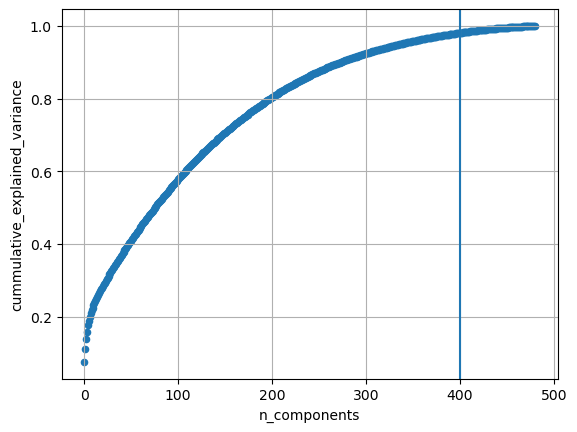

In [118]:
(
    pd.Series(projection_pipeline['pca'].explained_variance_ratio_)
        .cumsum()
        .to_frame()
        .reset_index()
        .rename(columns={'index': 'n_components', 0: 'cummulative_explained_variance'})
        .plot.scatter(x='n_components', y='cummulative_explained_variance')
)
plt.grid()
plt.axvline(N_PCS)

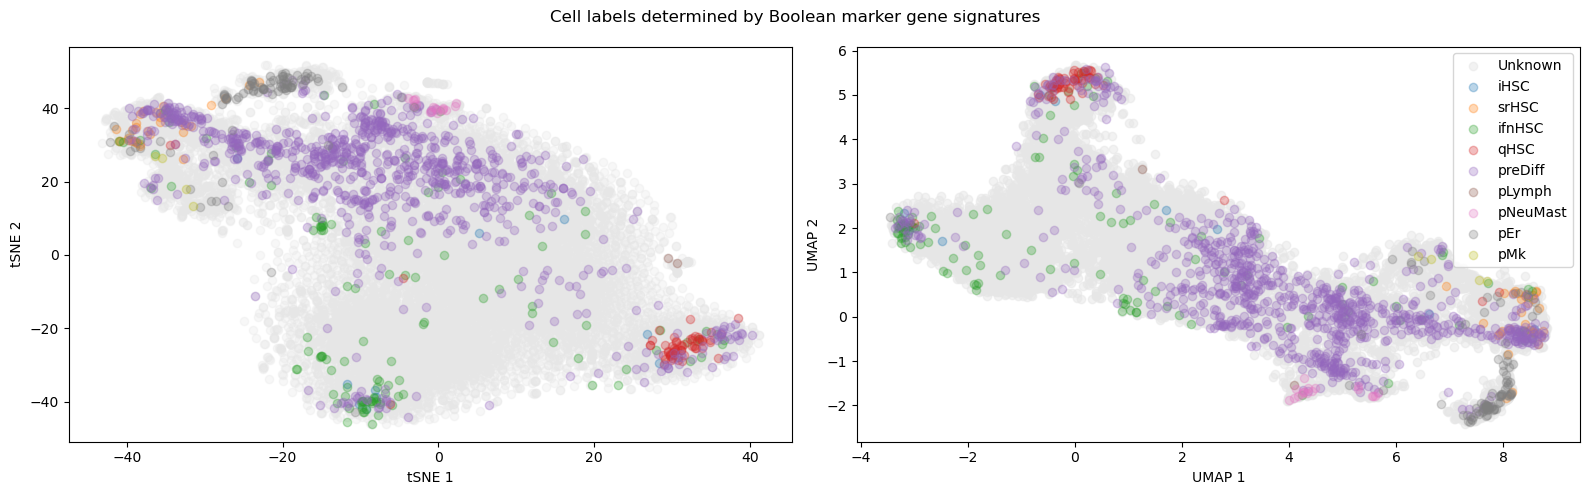

In [119]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(16,5))

_tsne_i = 0
_umap_i = 1
_ = axs[_umap_i].scatter(projected_umap.loc[unlabelled_idx, 0], projected_umap.loc[unlabelled_idx, 1], label="Unknown", alpha=.5, c=color_map["Unknown"])
for name, idx in unambiguous_observations.items():
        _x, _y = projected_umap.loc[idx, 0], projected_umap.loc[idx, 1]
        axs[_umap_i].scatter(_x, _y, label=name, alpha=1 if name == 'HC' else .3)#, c=color_map[name])

axs[_umap_i].set_xlabel("UMAP 1")
axs[_umap_i].set_ylabel("UMAP 2")
#axs[0].legend()

_xname = projected_tsne.columns[0]
_yname = projected_tsne.columns[1]
_ = axs[_tsne_i].scatter(projected_tsne.loc[unlabelled_idx, _xname], projected_tsne.loc[unlabelled_idx, _yname], label="Unknown", alpha=.3, c=color_map["Unknown"])
for name, idx in unambiguous_observations.items():
        _x, _y = projected_tsne.loc[idx, _xname], projected_tsne.loc[idx, _yname]
        axs[_tsne_i].scatter(_x, _y, label=name, alpha=1 if name == 'HC' else .3)#, c=color_map[name])
axs[_tsne_i].set_xlabel("tSNE 1")
axs[_tsne_i].set_ylabel("tSNE 2")
#axs[1].legend()
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys())

plt.suptitle("Cell labels determined by Boolean marker gene signatures")
fig.tight_layout()

In [120]:
isolated_cells = (
    projected_umap
        .rename(columns={c: f"umap_{c}" for c in projected_umap.columns})
        .query("umap_0 > umap_0.mean() & umap_1 < 0")
        .index
)

In [121]:
print(f"{100*isolated_cells.shape[0]/data.shape[0]:.1f}% of cells are in this region/cluster")

16.7% of cells are in this region/cluster


In [122]:
isolated_cells_labels: set = set()
for name, idx in unambiguous_observations.items():
    if isolated_cells.isin(idx).any():
        isolated_cells_labels.update({name})
        
isolated_cells_labels

{'iHSC', 'ifnHSC', 'pEr', 'pLymph', 'pNeuMast', 'preDiff', 'srHSC'}

## Clustering and label propagation

In [123]:
sc.__version__

'1.11.5'

In [124]:
adata = sc.AnnData(data, dtype=np.float64)
adata

AnnData object with n_obs × n_vars = 14915 × 481

In [125]:
sc.pp.pca(adata, n_comps=N_PCS)

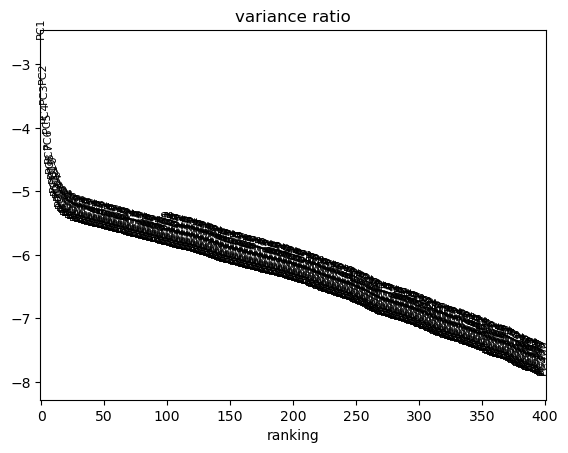

In [126]:
sc.pl.pca_variance_ratio(adata, log=True, n_pcs=N_PCS)

In [131]:
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=N_PCS)
adata

AnnData object with n_obs × n_vars = 14915 × 481
    uns: 'pca', 'neighbors'
    obsm: 'X_pca'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

In [132]:
sc.tl.louvain(adata)

In [133]:
100 * adata.obs.louvain.value_counts() / data.shape[0]

louvain
0    22.976869
1    22.319812
2    21.126383
3    10.224606
4     9.487094
5     7.207509
6     3.915521
7     2.742206
Name: count, dtype: float64

In [134]:
gg_umap = projected_umap.join(adata.obs.louvain).copy(deep=True).rename(columns={0: 'umap_1', 1: 'umap_2'})
gg_tsne = projected_tsne.join(adata.obs.louvain).copy(deep=True).rename(columns={0: 't-SNE_1', 1: 't-SNE_2'})

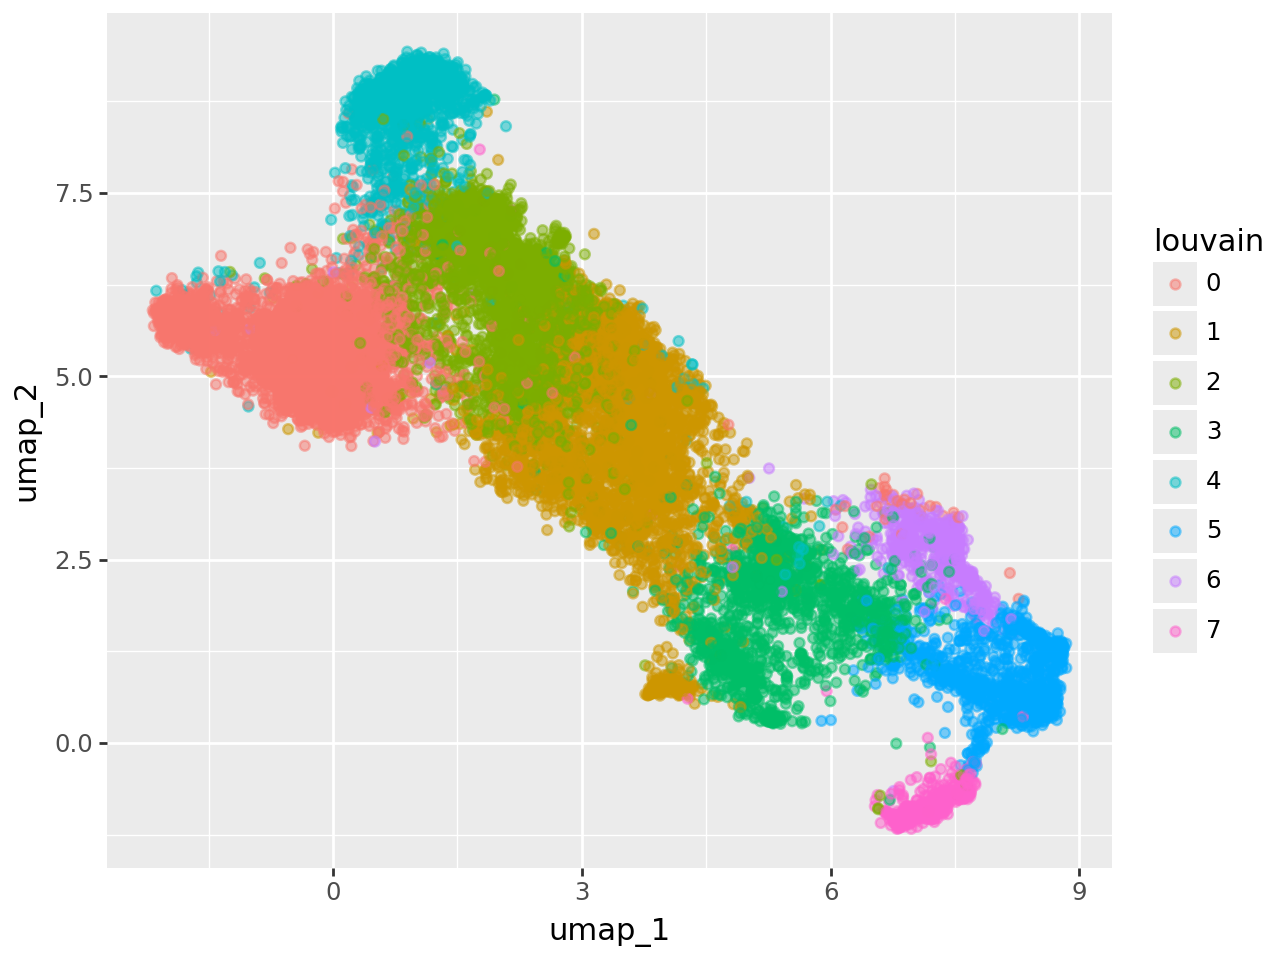

In [135]:
_plot_frame = gg_umap
first_plot = (
    ggplot(_plot_frame, aes(x=_plot_frame.columns[0], y=_plot_frame.columns[1]))
        + geom_point(aes(color='louvain'), alpha=.5)
)
first_plot

In [136]:
_to_discard = _plot_frame.query("umap_1 > umap_1.mean() & umap_2 < 0").louvain.unique()
_to_discard

['7', '3', '5', '2', '6']
Categories (8, object): ['0', '1', '2', '3', '4', '5', '6', '7']

In [137]:
discarded_louvain = _to_discard[0]
discarded_louvain

'7'

In [138]:
pheno_by_cluster = {}
for clus, frame in _plot_frame.groupby('louvain'):
    louv_idx = frame.index
    pheno_by_cluster.update({
        clus: {
            pheno: louv_idx.isin(pheno_idx).sum()
            for pheno, pheno_idx
            in unambiguous_observations.items()
        }
    })

pheno_by_cluster

{'0': {'iHSC': np.int64(0),
  'srHSC': np.int64(52),
  'ifnHSC': np.int64(48),
  'qHSC': np.int64(60),
  'preDiff': np.int64(64),
  'pLymph': np.int64(26),
  'pNeuMast': np.int64(4),
  'pEr': np.int64(0),
  'pMk': np.int64(2)},
 '1': {'iHSC': np.int64(0),
  'srHSC': np.int64(67),
  'ifnHSC': np.int64(22),
  'qHSC': np.int64(46),
  'preDiff': np.int64(350),
  'pLymph': np.int64(16),
  'pNeuMast': np.int64(120),
  'pEr': np.int64(0),
  'pMk': np.int64(4)},
 '2': {'iHSC': np.int64(0),
  'srHSC': np.int64(41),
  'ifnHSC': np.int64(9),
  'qHSC': np.int64(9),
  'preDiff': np.int64(55),
  'pLymph': np.int64(10),
  'pNeuMast': np.int64(12),
  'pEr': np.int64(1),
  'pMk': np.int64(2)},
 '3': {'iHSC': np.int64(0),
  'srHSC': np.int64(32),
  'ifnHSC': np.int64(5),
  'qHSC': np.int64(8),
  'preDiff': np.int64(173),
  'pLymph': np.int64(19),
  'pNeuMast': np.int64(180),
  'pEr': np.int64(1),
  'pMk': np.int64(5)},
 '4': {'iHSC': np.int64(0),
  'srHSC': np.int64(31),
  'ifnHSC': np.int64(14),
  'qHS

In [139]:
majority_pheno_by_cluster = {}
for clus, votes in pheno_by_cluster.items():
    votes = sorted(votes.items(), key=lambda item: item[1], reverse=True)
    _total = sum(v for _, v in votes)
    relative_votes = [(name, v/_total) for name, v in votes] 
    print(clus, relative_votes)
    majority_pheno_by_cluster.update({clus: relative_votes[0][0]})

0 [('preDiff', np.float64(0.25)), ('qHSC', np.float64(0.234375)), ('srHSC', np.float64(0.203125)), ('ifnHSC', np.float64(0.1875)), ('pLymph', np.float64(0.1015625)), ('pNeuMast', np.float64(0.015625)), ('pMk', np.float64(0.0078125)), ('iHSC', np.float64(0.0)), ('pEr', np.float64(0.0))]
1 [('preDiff', np.float64(0.56)), ('pNeuMast', np.float64(0.192)), ('srHSC', np.float64(0.1072)), ('qHSC', np.float64(0.0736)), ('ifnHSC', np.float64(0.0352)), ('pLymph', np.float64(0.0256)), ('pMk', np.float64(0.0064)), ('iHSC', np.float64(0.0)), ('pEr', np.float64(0.0))]
2 [('preDiff', np.float64(0.39568345323741005)), ('srHSC', np.float64(0.2949640287769784)), ('pNeuMast', np.float64(0.08633093525179857)), ('pLymph', np.float64(0.07194244604316546)), ('ifnHSC', np.float64(0.06474820143884892)), ('qHSC', np.float64(0.06474820143884892)), ('pMk', np.float64(0.014388489208633094)), ('pEr', np.float64(0.007194244604316547)), ('iHSC', np.float64(0.0))]
3 [('pNeuMast', np.float64(0.425531914893617)), ('preD

In [140]:
represented_by_louvain = set(majority_pheno_by_cluster.values())
phenotypes = set(unambiguous_observations)

In [141]:
100 * len(represented_by_louvain.intersection(phenotypes)) / len(phenotypes)

55.55555555555556

In [142]:
phenotypes.difference(represented_by_louvain)

{'iHSC', 'ifnHSC', 'pLymph', 'srHSC'}

In [143]:
_new_plot = _plot_frame.join(_plot_frame.louvain.map(majority_pheno_by_cluster).to_frame().rename(columns={"louvain": "phenotype"}))
_new_plot.head()

,umap_1,umap_2,louvain,phenotype
AAACCTGAGTTCGATC-1_0,3.443512,3.647621,1,preDiff
AAACCTGCAATCGGTT-1_0,2.669552,5.096971,1,preDiff
AAACCTGCACACGCTG-1_0,5.077337,1.433628,3,pNeuMast
AAACCTGCACGGATAG-1_0,5.160837,1.240942,3,pNeuMast
AAACCTGCATCATCCC-1_0,5.352273,2.635524,3,pNeuMast


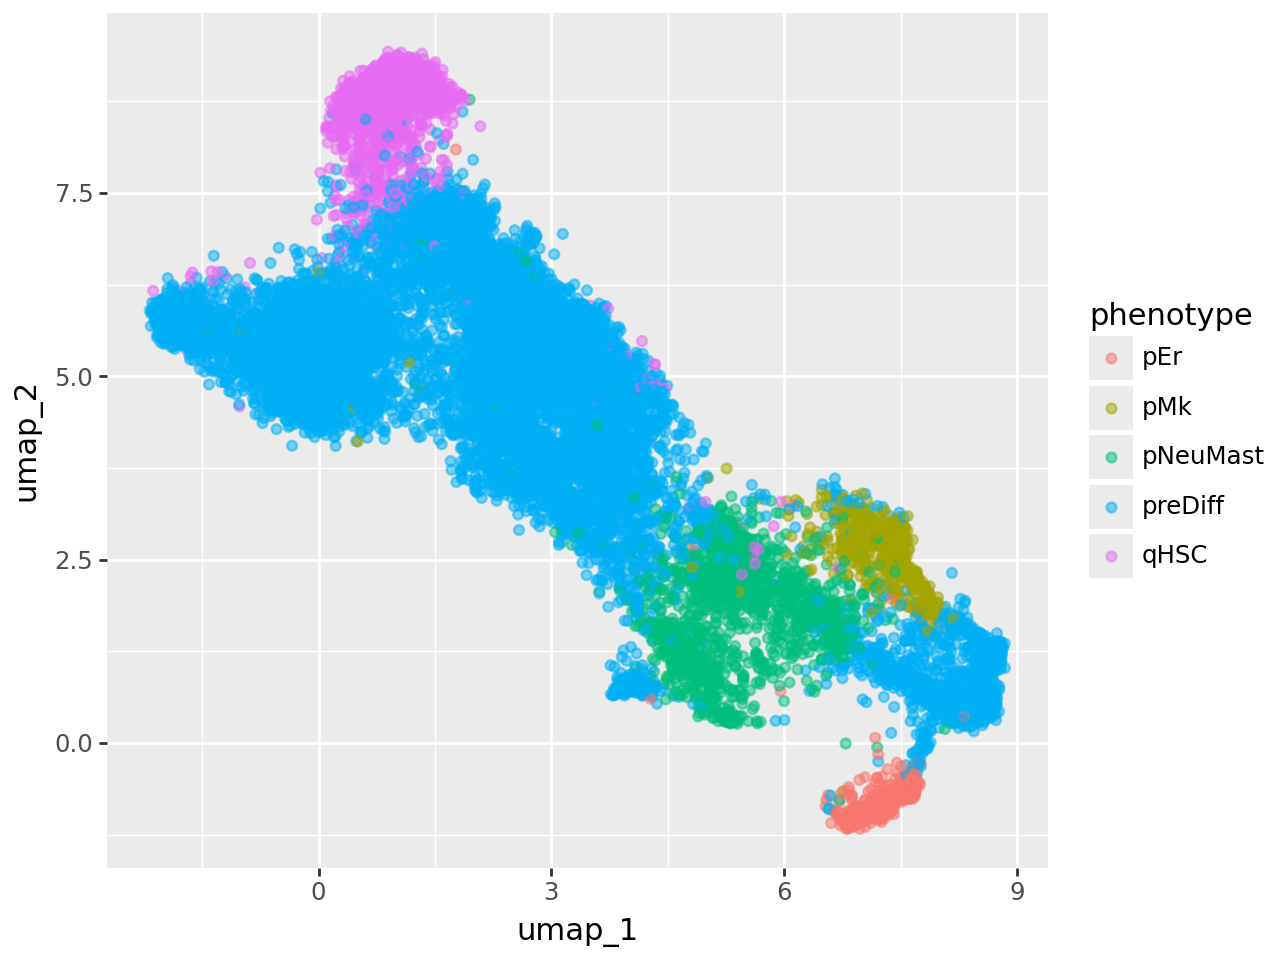

In [144]:
second_plot = (
    ggplot(_new_plot, aes(x=_plot_frame.columns[0], y=_plot_frame.columns[1]))
        + geom_point(aes(color='phenotype'), alpha=.5)
)
second_plot

In [145]:
palette = sns.color_palette('Set2', _plot_frame.louvain.unique().shape[0])
palette.as_hex()

['#66c2a5',
 '#fc8d62',
 '#8da0cb',
 '#e78ac3',
 '#a6d854',
 '#ffd92f',
 '#e5c494',
 '#b3b3b3']

In [146]:
final_color_map = dict(zip(_new_plot.phenotype.unique(),palette.as_hex()))
final_color_map

{'preDiff': '#66c2a5',
 'pNeuMast': '#fc8d62',
 'pMk': '#8da0cb',
 'pEr': '#e78ac3',
 'qHSC': '#a6d854'}

In [147]:
metadata = pd.DataFrame({
    'label': _new_plot.phenotype,
    'label_color': _new_plot.phenotype.map(final_color_map),
    'louvain': _new_plot.louvain,
})
metadata.loc[:, 'discard'] = False
metadata.loc[metadata.louvain == discarded_louvain, 'discard'] = True
metadata.head()

,label,label_color,louvain,discard
AAACCTGAGTTCGATC-1_0,preDiff,#66c2a5,1,False
AAACCTGCAATCGGTT-1_0,preDiff,#66c2a5,1,False
AAACCTGCACACGCTG-1_0,pNeuMast,#fc8d62,3,False
AAACCTGCACGGATAG-1_0,pNeuMast,#fc8d62,3,False
AAACCTGCATCATCCC-1_0,pNeuMast,#fc8d62,3,False


In [148]:
metadata.discard.value_counts()

discard
False    14506
True       409
Name: count, dtype: int64

## Leiden

In [127]:
sc.pp.neighbors(adata, n_pcs=N_PCS)
sc.tl.umap(adata)

In [128]:
%%time
sc.tl.leiden(
    adata, key_added="leiden_res0_25", resolution=0.25, flavor="igraph", n_iterations=2
)

CPU times: user 181 ms, sys: 6.94 ms, total: 188 ms
Wall time: 208 ms


In [129]:
sc.tl.leiden(
    adata, key_added="leiden_res0_5", resolution=0.5, flavor="igraph", n_iterations=2
)

In [130]:
sc.tl.leiden(
    adata, key_added="leiden_res1", resolution=1.0, flavor="igraph", n_iterations=2
)

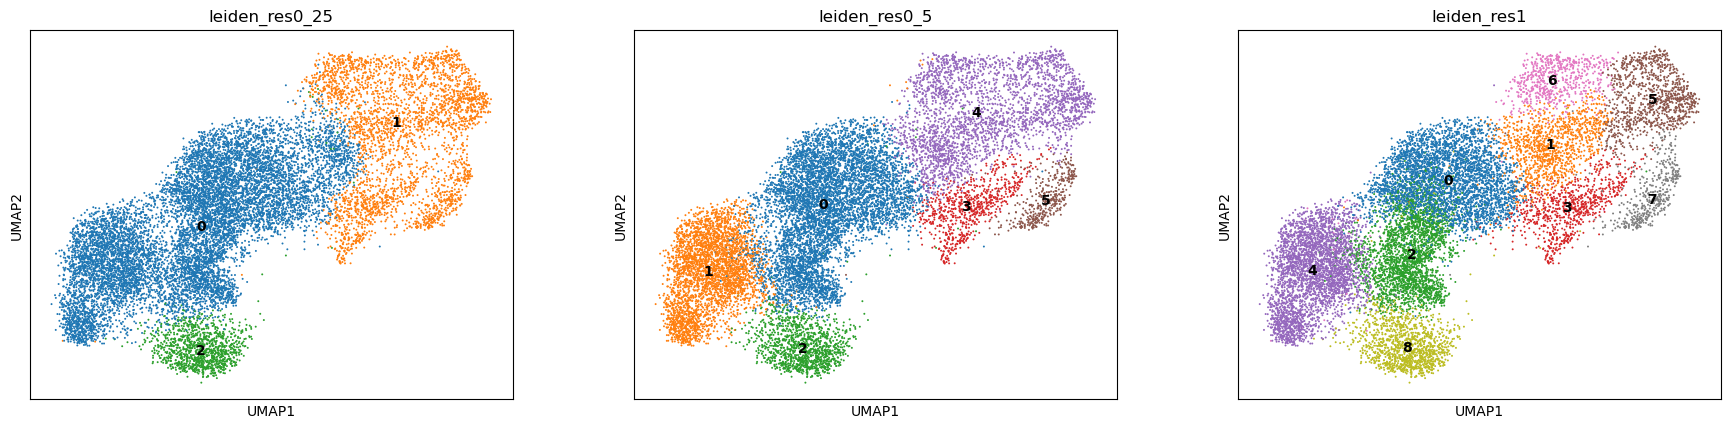

In [131]:
sc.pl.umap(
    adata,
    color=["leiden_res0_25", "leiden_res0_5", "leiden_res1"],
    legend_loc="on data",
)

In [132]:
sc.tl.leiden(
    adata, resolution=1.0, flavor="igraph", n_iterations=2
)

In [133]:
100 * adata.obs.leiden.value_counts() / data.shape[0]

leiden
0    24.123366
4    22.085149
2    17.861214
8     8.856856
1     7.589675
5     6.751592
3     5.464298
6     4.270868
7     2.996983
Name: count, dtype: float64

In [134]:
gg_umap = projected_umap.join(adata.obs.leiden).copy(deep=True).rename(columns={0: 'umap_1', 1: 'umap_2'})
gg_tsne = projected_tsne.join(adata.obs.leiden).copy(deep=True).rename(columns={0: 't-SNE_1', 1: 't-SNE_2'})

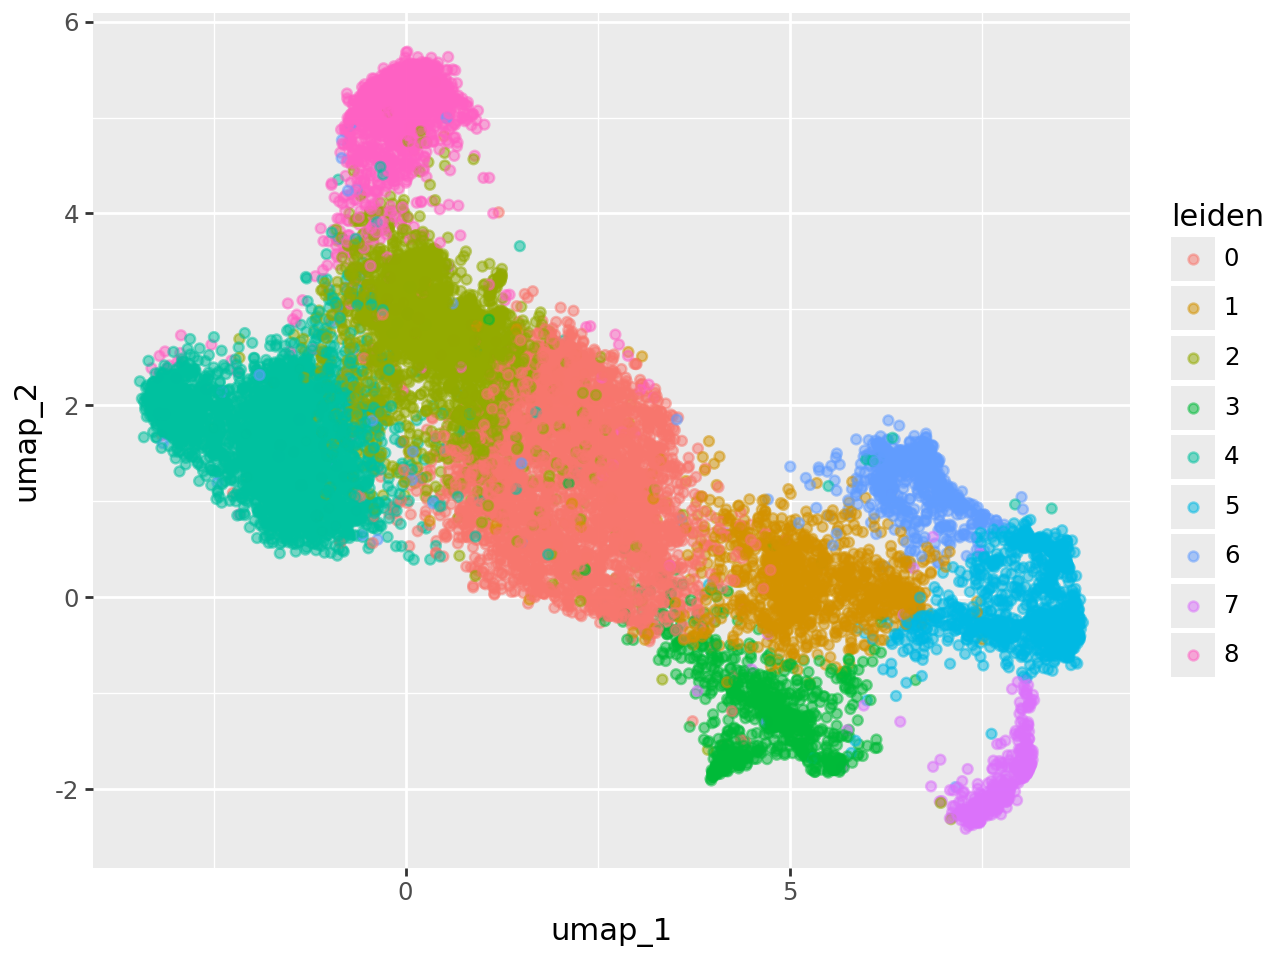

In [135]:
_plot_frame = gg_umap
first_plot = (
    ggplot(_plot_frame, aes(x=_plot_frame.columns[0], y=_plot_frame.columns[1]))
        + geom_point(aes(color='leiden'), alpha=.5)
)
first_plot

In [136]:
_to_discard = _plot_frame.query("umap_1 > umap_1.mean() & umap_2 < 0").leiden.unique()
_to_discard

['3', '1', '5', '7', '0', '2', '6']
Categories (9, object): ['0', '1', '2', '3', ..., '5', '6', '7', '8']

In [137]:
discarded_leiden = _to_discard[0]
discarded_leiden

'3'

In [138]:
pheno_by_cluster = {}
for clus, frame in _plot_frame.groupby('leiden'):
    louv_idx = frame.index
    pheno_by_cluster.update({
        clus: {
            pheno: louv_idx.isin(pheno_idx).sum()
            for pheno, pheno_idx
            in unambiguous_observations.items()
        }
    })

pheno_by_cluster

{'0': {'iHSC': np.int64(2),
  'srHSC': np.int64(0),
  'ifnHSC': np.int64(23),
  'qHSC': np.int64(0),
  'preDiff': np.int64(294),
  'pLymph': np.int64(0),
  'pNeuMast': np.int64(0),
  'pEr': np.int64(0),
  'pMk': np.int64(0)},
 '1': {'iHSC': np.int64(1),
  'srHSC': np.int64(0),
  'ifnHSC': np.int64(9),
  'qHSC': np.int64(0),
  'preDiff': np.int64(215),
  'pLymph': np.int64(0),
  'pNeuMast': np.int64(0),
  'pEr': np.int64(1),
  'pMk': np.int64(0)},
 '2': {'iHSC': np.int64(0),
  'srHSC': np.int64(0),
  'ifnHSC': np.int64(9),
  'qHSC': np.int64(0),
  'preDiff': np.int64(26),
  'pLymph': np.int64(1),
  'pNeuMast': np.int64(0),
  'pEr': np.int64(1),
  'pMk': np.int64(0)},
 '3': {'iHSC': np.int64(0),
  'srHSC': np.int64(0),
  'ifnHSC': np.int64(2),
  'qHSC': np.int64(0),
  'preDiff': np.int64(99),
  'pLymph': np.int64(1),
  'pNeuMast': np.int64(18),
  'pEr': np.int64(2),
  'pMk': np.int64(0)},
 '4': {'iHSC': np.int64(5),
  'srHSC': np.int64(0),
  'ifnHSC': np.int64(51),
  'qHSC': np.int64(1),

In [139]:
majority_pheno_by_cluster = {}
for clus, votes in pheno_by_cluster.items():
    votes = sorted(votes.items(), key=lambda item: item[1], reverse=True)
    _total = sum(v for _, v in votes)
    relative_votes = [(name, v/_total) for name, v in votes] 
    print(clus, relative_votes)
    majority_pheno_by_cluster.update({clus: relative_votes[0][0]})

0 [('preDiff', np.float64(0.9216300940438872)), ('ifnHSC', np.float64(0.07210031347962383)), ('iHSC', np.float64(0.006269592476489028)), ('srHSC', np.float64(0.0)), ('qHSC', np.float64(0.0)), ('pLymph', np.float64(0.0)), ('pNeuMast', np.float64(0.0)), ('pEr', np.float64(0.0)), ('pMk', np.float64(0.0))]
1 [('preDiff', np.float64(0.9513274336283186)), ('ifnHSC', np.float64(0.03982300884955752)), ('iHSC', np.float64(0.004424778761061947)), ('pEr', np.float64(0.004424778761061947)), ('srHSC', np.float64(0.0)), ('qHSC', np.float64(0.0)), ('pLymph', np.float64(0.0)), ('pNeuMast', np.float64(0.0)), ('pMk', np.float64(0.0))]
2 [('preDiff', np.float64(0.7027027027027027)), ('ifnHSC', np.float64(0.24324324324324326)), ('pLymph', np.float64(0.02702702702702703)), ('pEr', np.float64(0.02702702702702703)), ('iHSC', np.float64(0.0)), ('srHSC', np.float64(0.0)), ('qHSC', np.float64(0.0)), ('pNeuMast', np.float64(0.0)), ('pMk', np.float64(0.0))]
3 [('preDiff', np.float64(0.8114754098360656)), ('pNeuMa

In [140]:
represented_by_leiden = set(majority_pheno_by_cluster.values())
phenotypes = set(unambiguous_observations)

In [141]:
100 * len(represented_by_leiden.intersection(phenotypes)) / len(phenotypes)

44.44444444444444

In [142]:
phenotypes.difference(represented_by_leiden)

{'iHSC', 'pLymph', 'pMk', 'pNeuMast', 'srHSC'}

In [143]:
_new_plot = _plot_frame.join(_plot_frame.leiden.map(majority_pheno_by_cluster).to_frame().rename(columns={"leiden": "phenotype"}))
_new_plot.head()

,umap_1,umap_2,leiden,phenotype
AAACCTGAGTTCGATC-1_0,3.057618,0.562871,0,preDiff
AAACCTGCAATCGGTT-1_0,1.643430,1.918404,0,preDiff
AAACCTGCACACGCTG-1_0,4.948336,-1.013512,3,preDiff
AAACCTGCACGGATAG-1_0,5.085875,-1.040196,3,preDiff
AAACCTGCATCATCCC-1_0,4.836488,0.463194,1,preDiff


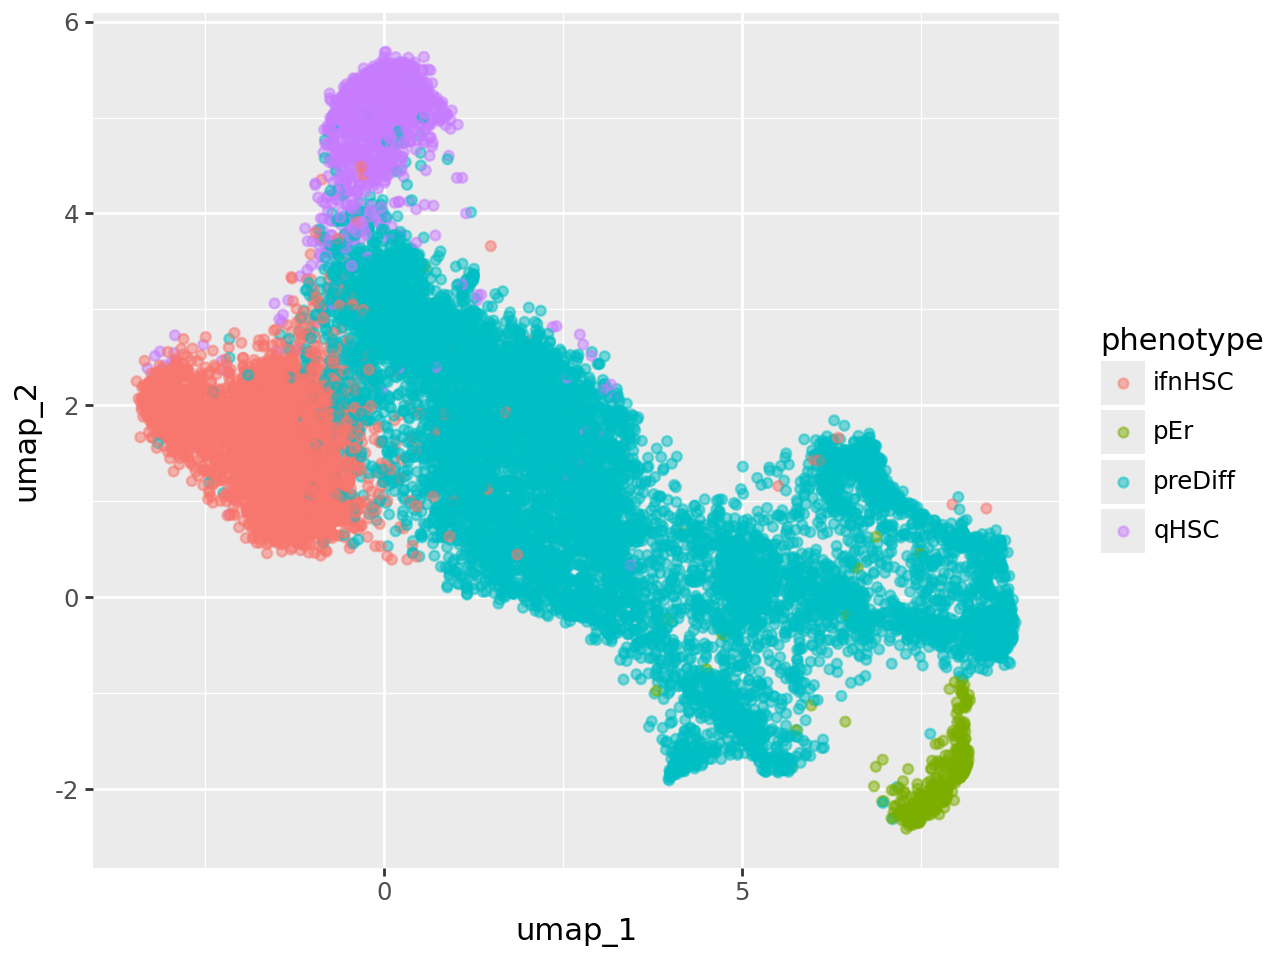

In [144]:
second_plot = (
    ggplot(_new_plot, aes(x=_plot_frame.columns[0], y=_plot_frame.columns[1]))
        + geom_point(aes(color='phenotype'), alpha=.5)
)
second_plot

In [145]:
palette = sns.color_palette('Set2', _plot_frame.leiden.unique().shape[0])
palette.as_hex()

['#66c2a5',
 '#fc8d62',
 '#8da0cb',
 '#e78ac3',
 '#a6d854',
 '#ffd92f',
 '#e5c494',
 '#b3b3b3',
 '#66c2a5']

In [146]:
final_color_map = dict(zip(_new_plot.phenotype.unique(),palette.as_hex()))
final_color_map

{'preDiff': '#66c2a5',
 'ifnHSC': '#fc8d62',
 'pEr': '#8da0cb',
 'qHSC': '#e78ac3'}

In [147]:
metadata = pd.DataFrame({
    'label': _new_plot.phenotype,
    'label_color': _new_plot.phenotype.map(final_color_map),
    'leiden': _new_plot.leiden,
})
metadata.loc[:, 'discard'] = False
metadata.loc[metadata.leiden == discarded_leiden, 'discard'] = True
metadata.head()

,label,label_color,leiden,discard
AAACCTGAGTTCGATC-1_0,preDiff,#66c2a5,0,False
AAACCTGCAATCGGTT-1_0,preDiff,#66c2a5,0,False
AAACCTGCACACGCTG-1_0,preDiff,#66c2a5,3,True
AAACCTGCACGGATAG-1_0,preDiff,#66c2a5,3,True
AAACCTGCATCATCCC-1_0,preDiff,#66c2a5,1,False


In [148]:
metadata.discard.value_counts()

discard
False    14100
True       815
Name: count, dtype: int64

## Automated annotation

### CellTypist

In [80]:
adata = sc.AnnData(data, dtype=np.float64)


In [81]:
adata.layers["counts"] = adata.X

In [82]:
adata_celltypist = adata.copy()  # make a copy of our adata
adata_celltypist.X = adata.layers["counts"]  # set adata.X to raw counts
sc.pp.normalize_total(
    adata_celltypist, target_sum=10**4
)  # normalize to 10,000 counts per cell
sc.pp.log1p(adata_celltypist)  # log-transform
# make .X dense instead of sparse, for compatibility with celltypist:
#adata_celltypist.X = adata_celltypist.X.toarray()

In [87]:
model_ultima = models.Model.load(model="Adult_cHSPCs_Ultima.pkl")
model_illumina = models.Model.load(model="Adult_cHSPCs_Illumina.pkl")

In [88]:
model_ultima.cell_types

array(['B', 'BEMP', 'CLP', 'DC', 'Doublet', 'ERYP', 'Endothel', 'GMP-L',
       'HSC_MPP', 'MEBEMP-L', 'MKP', 'Monocyte', 'NK/T', 'NKTDP',
       'high_MPP_sig_ERYP', 'mregDC', 'plasmablast', 'pre-B?', 'pro-B?',
       'unassigned'], dtype=object)

## scArches

In [92]:
adata_query.obs['cell_type']

0                                    naive T cell
1                    hematopoietic precursor cell
2                                        monocyte
3         megakaryocyte-erythroid progenitor cell
4                         granulocytopoietic cell
                           ...                   
199694                    hematopoietic stem cell
199695                               naive B cell
199696                           precursor B cell
199697                    hematopoietic stem cell
199698            CD4-positive, alpha-beta T cell
Name: cell_type, Length: 199699, dtype: object

In [7]:
import cellxgene_census
import scvi

In [10]:
%%time
census = cellxgene_census.open_soma(census_version="2023-12-15")

CPU times: user 134 ms, sys: 41.8 ms, total: 176 ms
Wall time: 1.79 s


In [11]:
%%time
# Pobieramy zdrowe mysie komórki szpiku, które posłużą jako MARROW REFERENCE
marrow_reference = cellxgene_census.get_anndata(
    census=census,
    measurement_name="RNA",
    organism="Mus musculus",
    obs_value_filter="tissue == 'bone marrow'",  # Wyciągamy tylko szpik kostny
    obs_embeddings=["scvi"]                      # Pobieramy gotowe osadzenie scVI
)

# W tym momencie obiekt `marrow_reference` zawiera już kolumnę z etykietami,
# np. marrow_reference.obs['cell_type'] z nazwami typu "HSC", "B cell" itd.

CPU times: user 3min 13s, sys: 4min 24s, total: 7min 37s
Wall time: 4min 48s


### Reference dataset characteristics

In [24]:
marrow_reference.var

,soma_joinid,feature_id,feature_name,feature_length,nnz,n_measured_obs
0,0,ENSMUSG00000051951,Xkr4,6094,2554222,5438693
1,1,ENSMUSG00000025900,Rp1,12311,41522,5010176
2,2,ENSMUSG00000025902,Sox17,4772,115768,5682918
3,3,ENSMUSG00000033845,Mrpl15,8487,1554247,5684805
4,4,ENSMUSG00000025903,Lypla1,7145,761343,5684805
...,...,...,...,...,...,...
52412,52412,ENSMUSG00000118733,U7_ENSMUSG00000118733,63,2,22375
52413,52413,ENSMUSG00000119262,U3_ENSMUSG00000119262,215,0,0
52414,52414,ENSMUSG00000119851,U3_ENSMUSG00000119851,215,1848,34834
52415,52415,ENSMUSG00000119761,U3_ENSMUSG00000119761,215,723,34834


In [12]:
marrow_reference.write_h5ad("marrow_reference_backup.h5ad")

... storing 'dataset_id' as categorical
... storing 'assay' as categorical
... storing 'assay_ontology_term_id' as categorical
... storing 'cell_type' as categorical
... storing 'cell_type_ontology_term_id' as categorical
... storing 'development_stage' as categorical
... storing 'development_stage_ontology_term_id' as categorical
... storing 'disease' as categorical
... storing 'disease_ontology_term_id' as categorical
... storing 'donor_id' as categorical
... storing 'self_reported_ethnicity' as categorical
... storing 'self_reported_ethnicity_ontology_term_id' as categorical
... storing 'sex' as categorical
... storing 'sex_ontology_term_id' as categorical
... storing 'suspension_type' as categorical
... storing 'tissue' as categorical
... storing 'tissue_ontology_term_id' as categorical
... storing 'tissue_general' as categorical
... storing 'tissue_general_ontology_term_id' as categorical


In [13]:
# ==============================================================================
# 2. PRZYGOTOWANIE MODELU REFERENCYJNEGO
# ==============================================================================
# Trenujemy model scVI na pobranej referencji ze szpiku
scvi.model.SCVI.setup_anndata(marrow_reference, batch_key="dataset_id")

In [14]:
vae_ref = scvi.model.SCVI(marrow_reference)

In [15]:
vae_ref.train()

INFO: GPU available: True (cuda), used: True
GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: You are using a CUDA device ('NVIDIA RTX PRO 500 Blackwell Generation Laptop GPU') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#

Training:   0%|          | 0/40 [00:00<?, ?it/s]

INFO: `Trainer.fit` stopped: `max_epochs=40` reached.
`Trainer.fit` stopped: `max_epochs=40` reached.


In [16]:
vae_ref.save("mus_marrow.pt")

In [17]:
data = pd.read_csv("dataset_hvgs.csv", index_col=0)
adata_herault = sc.AnnData(data, dtype=np.float64)

### AnnData preparation

In [19]:
adata_to_map = adata_herault.copy()
'''for layer in list(adata_to_map.layers.keys()):
    if layer != "counts":
        del adata_to_map.layers[layer]
adata_to_map.X = adata_to_map.layers["counts"]'''

KeyError: 'counts'

In [20]:
adata_to_map.var["gene_names"] = adata_to_map.var.index
adata_to_map.var.set_index("gene_id", inplace=True)

KeyError: "None of ['gene_id'] are in the columns"

In [21]:
vae_ref["gene_names"]

TypeError: 'SCVI' object is not subscriptable

In [22]:
reference_model_features["gene_names"] = marrow_reference.index
reference_model_features.set_index("gene_ids", inplace=True)

AttributeError: 'AnnData' object has no attribute 'index'

In [ ]:
# ==============================================================================
# 3. ZASTOSOWANIE SCARCHES NA TWOICH DANYCH (QUERY = HÉRAULT)
# ==============================================================================
# adata_herault to Twój surowy plik AnnData z komórkami, które chcesz nazwać
#adata_herault = scvi.read("scHSC_herault.h5ad") 

In [18]:
# scArches przygotowuje Twoje query (Hérault) pod model referencyjny
scvi.model.SCVI.prepare_query_anndata(adata_herault, vae_ref)

# Ładujemy model dla danych Hérault przy użyciu operacji "architecture surgery"
vae_q = scvi.model.SCVI.load_query_data(adata_herault, vae_ref)

ValueError: No reference var names found in query data. Please rerun with return_reference_var_names=True to see reference var names.

In [ ]:
vae_q.train(max_epochs=20)  # Szybkie dotrenowanie samych wag wejściowych dla query

In [ ]:
# Wyciągamy reprezentację ukrytą dla komórek Hérault zmapowaną na zdrowy szpik
adata_herault.obsm["X_scvi"] = vae_q.get_latent_representation()

In [ ]:
cvi"] = vae_q.get_latent_representation()

## Exporting metadata

In [149]:
metadata.to_csv("cell_annotation_metadata.tsv", sep="\t")

In [150]:
metadata

,label,label_color,leiden,discard
AAACCTGAGTTCGATC-1_0,preDiff,#66c2a5,0,False
AAACCTGCAATCGGTT-1_0,preDiff,#66c2a5,0,False
AAACCTGCACACGCTG-1_0,preDiff,#66c2a5,3,True
AAACCTGCACGGATAG-1_0,preDiff,#66c2a5,3,True
AAACCTGCATCATCCC-1_0,preDiff,#66c2a5,1,False
...,...,...,...,...
TTTGTCAGTCTTGTCC-1_3,ifnHSC,#fc8d62,4,False
TTTGTCAGTGGTAACG-1_3,preDiff,#66c2a5,6,False
TTTGTCATCAACCAAC-1_3,preDiff,#66c2a5,6,False
TTTGTCATCACAGGCC-1_3,preDiff,#66c2a5,2,False
